In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv("../data/crop_production.csv")
print(df.shape)
df.info()

(246091, 7)
<class 'pandas.DataFrame'>
RangeIndex: 246091 entries, 0 to 246090
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   State_Name     246091 non-null  str    
 1   District_Name  246091 non-null  str    
 2   Crop_Year      246091 non-null  int64  
 3   Season         246091 non-null  str    
 4   Crop           246091 non-null  str    
 5   Area           246091 non-null  float64
 6   Production     242361 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 13.1 MB


In [3]:
df.head()

,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0


In [4]:
df.isna().sum()

State_Name          0
District_Name       0
Crop_Year           0
Season              0
Crop                0
Area                0
Production       3730
dtype: int64

In [5]:
df.columns=df.columns.str.strip().str.lower()
df=df.rename(columns={"state_name":"state","district_name": "district", "crop_year": "year"})

for col in ['state','district','season','crop']:
    df[col]=df[col].str.strip()

df['season'].unique()


<StringArray>
['Kharif', 'Whole Year', 'Autumn', 'Rabi', 'Summer', 'Winter']
Length: 6, dtype: str

In [6]:
print("before: ",len(df))
df=df.dropna(subset=["production"])
df=df[(df['area']>0 ) & (df["production"] >0)]
df=df.drop_duplicates()
print("after: ", len(df))

before:  246091
after:  238838


In [8]:
df["yield_t_per_ha"]=df["production"]/df["area"]
df[["area",'production','yield_t_per_ha']].describe()

,area,production,yield_t_per_ha
count,2.388380e+05,2.388380e+05,238838.000000
mean,1.234239e+04,5.910957e+05,42.263407
std,5.120969e+04,1.719107e+07,823.564866
min,1.000000e-01,1.000000e-02,0.000003
25%,9.100000e+01,9.900000e+01,0.532242
50%,6.340550e+02,7.840000e+02,1.000000
75%,4.700000e+03,7.306270e+03,2.400000
max,8.580100e+06,1.250800e+09,88000.000000


In [9]:
df.groupby("year").size()

year
1997     8899
1998    11262
1999    12282
2000    13401
2001    13139
2002    15094
2003    15550
2004    13834
2005    13519
2006    13976
2007    14269
2008    14230
2009    13767
2010    13793
2011    13791
2012    13183
2013    13474
2014    10814
2015      561
dtype: int64

In [10]:
df = df[df["year"] < 2015] 

In [11]:
#Dropped rows with missing production because yield can’t be calculated

In [12]:
#Charts

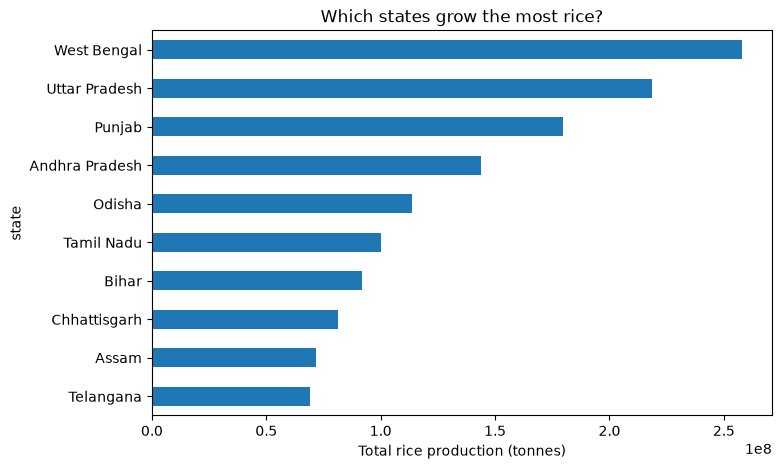

In [19]:
rice=df[df['crop']=='Rice']
top= rice.groupby('state')["production"].sum().nlargest(10).sort_values()
top.plot(kind="barh", figsize=(8,5))
plt.title("Which states grow the most rice?")
plt.xlabel("Total rice production (tonnes)")
plt.show()

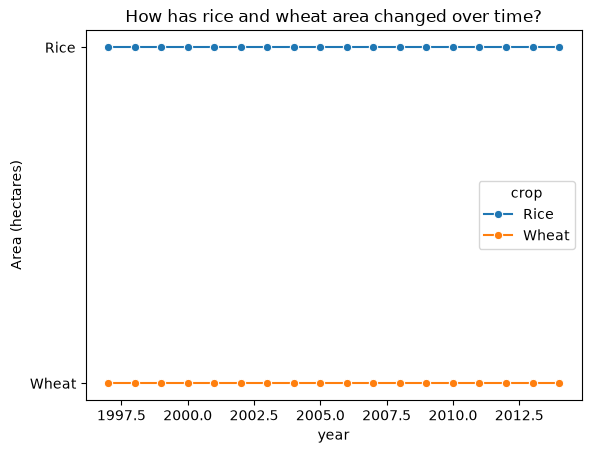

In [20]:
trend=(df[df['crop'].isin(['Rice','Wheat'])].groupby(['year','crop'])['area'].sum().reset_index())
sns.lineplot(data=trend,x='year',y='crop',hue='crop',marker='o')
plt.title("How has rice and wheat area changed over time?")
plt.ylabel("Area (hectares)")
plt.show()

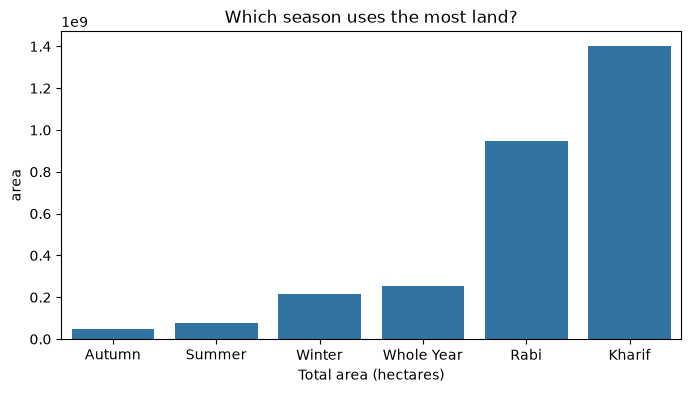

In [21]:
season_area=df.groupby('season')['area'].sum().sort_values()
plt.figure(figsize=(8, 4))
sns.barplot(data=season_area)
plt.title("Which season uses the most land?")
plt.xlabel("Total area (hectares)")
plt.show()

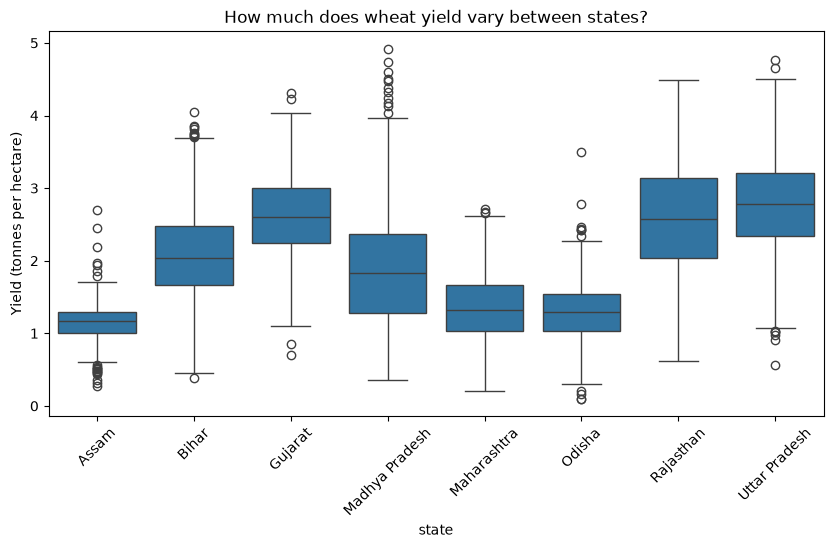

In [23]:
wheat=df[df['crop']=='Wheat']
states=wheat['state'].value_counts().head(8).index
plt.figure(figsize=(10, 5))
sns.boxplot(data=wheat[wheat["state"].isin(states)],x="state", y="yield_t_per_ha")
plt.xticks(rotation=45)
plt.title("How much does wheat yield vary between states?")
plt.ylabel("Yield (tonnes per hectare)")
plt.show()

<Figure size 1200x500 with 0 Axes>

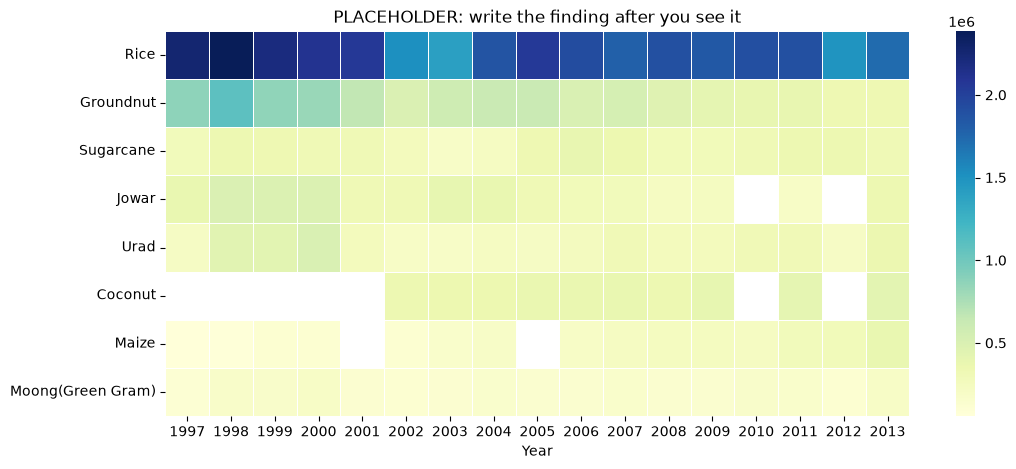

In [32]:
tn = df[df["state"] == "Tamil Nadu"]
tn = tn[~tn["crop"].str.startswith("Total")] 
top_crops = tn.groupby("crop")["area"].sum().nlargest(8).index
plt.figure(figsize=(12, 5))
pivot = (tn[tn["crop"].isin(top_crops)]
         .pivot_table(index="crop", columns="year", values="area", aggfunc="sum"))
pivot = pivot.loc[top_crops]  
plt.figure(figsize=(12, 5))
sns.heatmap(pivot, cmap="YlGnBu", linewidths=0.5)
plt.title("PLACEHOLDER: write the finding after you see it")
plt.xlabel("Year")
plt.ylabel("")
plt.show()

##Findings 
1. **Rice leaders:** West Bengal (258,092,849) plus Uttar Pradesh (218,793,359) is about 477 million tonnes, and the printed share is 29.8%
2. 
3. **Trend:** 30,706,467 in 1997 and 39,087,673 in 2014. The gain is 8.4 million, and 8.4 ÷ 30.7 ≈ 27%.

4. **Seasons:** Kharif uses about 1.48 times as much land as Rabi
5. 
6. **Wheat yield:** Among the eight states with the most wheat records, median yield is highest in Uttar Pradesh (2.78 t/ha) and lowest in Assam (1.18 t/ha), more than double.
7. 
8. **Tamil Nadu:** Rice covers about 1.9 million hectares per year in Tamil Nadu, over three times as much as the next crop, groundnut (about 0.6 million).


In [31]:
# Finding 1: top 2 rice states and their share of all rice production
lead = top.tail(2)
print("1.", lead.round(0).to_dict())
print("   share of all rice production: %.1f%%" % (lead.sum() / rice["production"].sum() * 100))

# Finding 2: rice area, first year vs last year
r = trend[trend["crop"] == "Rice"].sort_values("year")
print("2.", r.iloc[0][["year", "area"]].tolist(), "->", r.iloc[-1][["year", "area"]].tolist())

# Finding 3: land by season, and the ratio of the top two
print("3.", season_area.sort_values(ascending=False).round(0).to_dict())

# Finding 4: wheat median yield by state (highest and lowest of the states in your box plot)
med = wheat[wheat["state"].isin(states)].groupby("state")["yield_t_per_ha"].median().sort_values()
print("4.", med.round(2).to_dict())

# Finding 5: Tamil Nadu average yearly area per crop (top 8)
print("5.", pivot.mean(axis=1).round(0).to_dict())

1. {'Uttar Pradesh': 218793359.0, 'West Bengal': 258092849.0}
   share of all rice production: 29.8%
2. [np.int64(1997), np.float64(30706467.0)] -> [np.int64(2014), np.float64(39087673.0)]
3. {'Kharif': 1403069358.0, 'Rabi': 947883280.0, 'Whole Year': 253844683.0, 'Winter': 216213670.0, 'Summer': 74819481.0, 'Autumn': 47401199.0}
4. {'Assam': 1.18, 'Odisha': 1.29, 'Maharashtra': 1.33, 'Madhya Pradesh': 1.83, 'Bihar': 2.04, 'Rajasthan': 2.58, 'Gujarat': 2.6, 'Uttar Pradesh': 2.78}
5. {'Rice': 1903016.0, 'Groundnut': 588526.0, 'Total foodgrain': 4046554.0, 'Sugarcane': 309953.0, 'Jowar': 345386.0, 'Urad': 291994.0, 'Coconut': 377718.0, 'Maize': 195415.0}
